README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Całkowita liczba dokumentów: 242
Całkowita liczba znaków po oczyszczeniu: 1943058

--- FRAGMENT PO OCZYSZCZENIU ---
AWK – interpretowany język programowania, którego główną funkcją jest wyszukiwanie i przetwarzanie wzorców w plikach lub strumieniach danych. Jest także nazwą programu początkowo dostępnego dla systemów operacyjnych będących pochodnymi UNIX-a, obecnie także na inne platformy.
AWK jest językiem, który w znacznym stopniu wykorzystuje tablice asocjacy
--------------------------------------------------

Rozmiar słownika (z <UNK>): 407

--- TEST KODOWANIA I DEKODOWANIA ---
Oryginał:   'AWK – interpretowany język programowania, którego główną fun'
ID (pierwsze 15): [35, 57, 45, 2, 378, 2, 75, 80, 86, 71, 84, 82, 84, 71, 86]
Odkodowane: 'AWK – interpretowany język programowania, którego główną fun'

Znaki spoza słownika treningowego w walidacji: {'ე', '۔', '⋅', 'ی', 'ვ', 'ლ', 'ב', 'ա', 'ს', '‑', 'ע', 'ა', 'ი', 'ո', 'Ա', 'ד', '∆', 'ջ', 'Ц', 'ם', 'ս', 'վ', 'დ', 'מ', 'თ', 'ռ', 'غ',

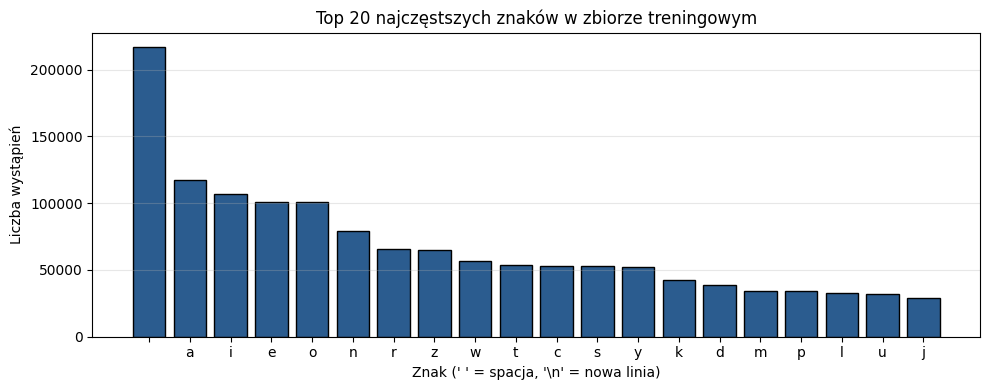

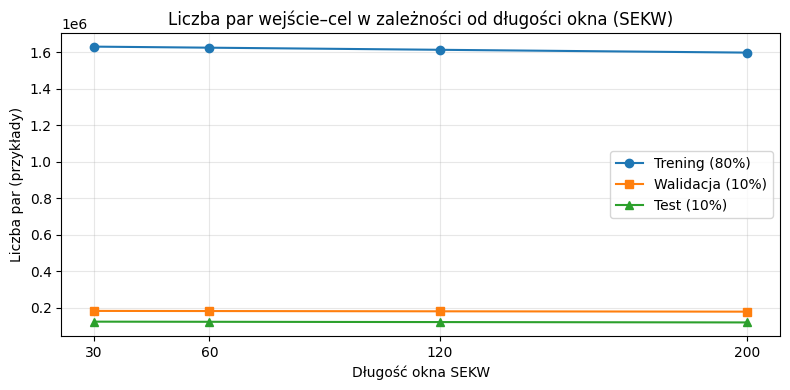

In [8]:
!pip -q install datasets

import re
from collections import Counter
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt
from datasets import load_dataset

torch.manual_seed(0)
np.random.seed(0)

ds_hf = load_dataset("wikiann", "pl", split="train[:3500]")
raw_docs = [" ".join(tokens) for tokens in ds_hf["tokens"]]

def clean_doc(text):
    text = re.sub(r"\s+([.,!?;:])", r"\1", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

docs = [clean_doc(d) for d in raw_docs if len(d) > 40]

n_docs = len(docs)
n_train_docs = int(0.8 * n_docs)
n_val_docs = int(0.9 * n_docs)

train_docs = docs[:n_train_docs]
val_docs = docs[n_train_docs:n_val_docs]
test_docs = docs[n_val_docs:]

train_text = "\n".join(train_docs)
val_text = "\n".join(val_docs)
test_text = "\n".join(test_docs)
total_chars = len(train_text) + len(val_text) + len(test_text)

print(f"Całkowita liczba dokumentów: {n_docs}")
print(f"Całkowita liczba znaków po oczyszczeniu: {total_chars}")
print("\n--- FRAGMENT PO OCZYSZCZENIU ---")
print(train_text[:350])
print("-" * 50)

UNK_TOKEN = "<UNK>"
chars = sorted(list(set(train_text)))
vocab = [UNK_TOKEN] + chars
char2idx = {ch: idx for idx, ch in enumerate(vocab)}
idx2char = {idx: ch for idx, ch in enumerate(vocab)}
vocab_size = len(vocab)

print(f"\nRozmiar słownika (z <UNK>): {vocab_size}")

def encode(text):
    unk_id = char2idx[UNK_TOKEN]
    return [char2idx.get(ch, unk_id) for ch in text]

def decode(ids):
    return "".join(idx2char[i] for i in ids)

sample_str = train_text[:60]
encoded_sample = encode(sample_str)
decoded_sample = decode(encoded_sample)
assert sample_str == decoded_sample

print("\n--- TEST KODOWANIA I DEKODOWANIA ---")
print(f"Oryginał:   {repr(sample_str)}")
print(f"ID (pierwsze 15): {encoded_sample[:15]}")
print(f"Odkodowane: {repr(decoded_sample)}")

oov_val = set(val_text) - set(chars)
oov_test = set(test_text) - set(chars)
print(f"\nZnaki spoza słownika treningowego w walidacji: {oov_val if oov_val else 'Brak (0)'}")
print(f"Znaki spoza słownika treningowego w teście:    {oov_test if oov_test else 'Brak (0)'}")

class CharDocsDataset(Dataset):
    def __init__(self, docs_list, seq_len):
        self.seq_len = seq_len
        self.samples = []
        for doc in docs_list:
            ids = encode(doc)
            if len(ids) > seq_len:
                for i in range(len(ids) - seq_len):
                    self.samples.append((ids[i : i + seq_len], ids[i + 1 : i + seq_len + 1]))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        x, y = self.samples[idx]
        return torch.tensor(x, dtype=torch.long), torch.tensor(y, dtype=torch.long)

SEKW_BAZOWE = 40
BATCH_SIZE = 128

ds_train = CharDocsDataset(train_docs, SEKW_BAZOWE)
ds_val = CharDocsDataset(val_docs, SEKW_BAZOWE)
ds_test = CharDocsDataset(test_docs, SEKW_BAZOWE)

dl_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True)
dl_val = DataLoader(ds_val, batch_size=BATCH_SIZE, shuffle=False)
dl_test = DataLoader(ds_test, batch_size=BATCH_SIZE, shuffle=False)

print("\n--- TABELA PODZIAŁU I LICZEBNOŚCI (SEKW = 40, BATCH = 128) ---")
for nazwa, d_list, txt, ds, dl in [
    ("Trening", train_docs, train_text, ds_train, dl_train),
    ("Walidacja", val_docs, val_text, ds_val, dl_val),
    ("Test", test_docs, test_text, ds_test, dl_test)
]:
    pct = 100.0 * len(txt) / total_chars
    uniq = len(set(txt))
    print(f"{nazwa:10s} | Dok: {len(d_list):4d} | Znaki: {len(txt):7d} ({pct:5.1f}%) | Unikalne: {uniq:3d} | Pary: {len(ds):7d} | Batche: {len(dl):5d}")

print("\n--- KONTROLA BATCHY I PAR WEJŚCIE-CEL ---")
for nazwa, dl in [("Trening", dl_train), ("Walidacja", dl_val), ("Test", dl_test)]:
    xb, yb = next(iter(dl))
    assert xb.shape == yb.shape and xb.shape[1] == SEKW_BAZOWE
    assert xb.min() >= 0 and xb.max() < vocab_size
    x_str = decode(xb[0].tolist())
    y_str = decode(yb[0].tolist())
    print(f"[{nazwa}] Kształt X: {tuple(xb.shape)}, Y: {tuple(yb.shape)} | Zakres ID: [{xb.min().item()}, {xb.max().item()}]")
    print(f"  Przykład X[0]: {repr(x_str)}")
    print(f"  Przykład Y[0]: {repr(y_str)}")

sekw_lista = [20, 40, 60, 80]
pary_train = [len(CharDocsDataset(train_docs, s)) for s in sekw_lista]
pary_val = [len(CharDocsDataset(val_docs, s)) for s in sekw_lista]
pary_test = [len(CharDocsDataset(test_docs, s)) for s in sekw_lista]

print("\n--- WPŁYW DŁUGOŚCI OKNA SEKW NA LICZBĘ PAR ---")
for s, ptr, pva, pte in zip(sekw_lista, pary_train, pary_val, pary_test):
    print(f"SEKW = {s:3d} | Trening: {ptr:7d} | Walidacja: {pva:6d} | Test: {pte:6d}")

counts = Counter(train_text)
top20 = counts.most_common(20)
labels_ch = [repr(k)[1:-1] if k in ['\n', ' '] else k for k, _ in top20]
vals_ch = [v for _, v in top20]

plt.figure(figsize=(10, 4))
plt.bar(labels_ch, vals_ch, color="#2b5c8f", edgecolor="black")
plt.title("Top 20 najczęstszych znaków w zbiorze treningowym")
plt.xlabel("Znak (' ' = spacja, '\\n' = nowa linia)")
plt.ylabel("Liczba wystąpień")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("czestosc_znakow.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(sekw_lista, pary_train, marker="o", label="Trening (80%)")
plt.plot(sekw_lista, pary_val, marker="s", label="Walidacja (10%)")
plt.plot(sekw_lista, pary_test, marker="^", label="Test (10%)")
plt.title("Liczba par wejście–cel w zależności od długości okna (SEKW)")
plt.xlabel("Długość okna SEKW")
plt.ylabel("Liczba par (przykłady)")
plt.xticks(sekw_lista)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("liczba_par_sekw.png", dpi=150)
plt.show()
